# ROI 25 — benchmark frontal face

script for single protein


## Classificazione

- **magenta:** frontal face rightly included in ROI;
- **rosso:** surface selected on ROI bur overestimated;
- **ciano:** portion of the frontal face not included in ROI;
- **verde:** tunnel exit;
- **grigio:** shell.

## Metriche principali

- `front_face_coverage_pct`: % of frontal face covered;
- `roi_overinclusion_pct`: % of ROI not part of the frontal face;
- `roi_precision_pct`: % of ROI calculated in a correct way;
- `missed_front_face_pct`: % of the frontal face remaning out of the ROI;
- `dice_score_pct`: Score matching ROI and frontal face.

 **surface proxy** are from shell points


In [61]:
from collections import deque
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


## Cella 2 — Paths and Paramiters

Depth of the frontal surface is of 7 A.
A frontal depth of 7 Å was selected as an operational geometric cutoff. This distance is comparable to approximately two consecutive Cα spacings and extends moderately beyond commonly used 4–6 Å heavy-atom contact definitions. It was therefore considered sufficient to include directly exposed and immediately recessed surface residues, while limiting the incorporation of deeper lateral regions that became evident with a 10 Å cutoff.


In [62]:
PROTEIN_NAME = "8WDW_UMGSP2"

COORD_LIST_FILE = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_0.5_bfactor/coord_lists/8WDW_UMGSP2_4rev_aligned_bfactor_coord_list.txt"
)

SHELL_PDB_FILE = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_0.5_bfactor/shells/8WDW_UMGSP2_4rev_aligned_shell.pdb"
)

ALIGNED_PROTEIN_PDB_FILE = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/enzymes_Review/pdb_files/pdb_aligned/8WDW_UMGSP2_4rev_aligned.pdb"
)

# Facoltativo: imposta None per non usarlo.
SMOOTHED_MATRIX_FILE = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/surfmap/output_SURFMAP_8WDW_UMGSP2_4rev_aligned_0.5_bfactor/smoothed_matrices/8WDW_UMGSP2_4rev_aligned_bfactor_smoothed_matrix.txt"
)

OUTPUT_DIR = Path(
    r"/home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI"
)

# ROI originale
ROI_RADIUS = 25
MAP_HEIGHT = 90
MAP_WIDTH = 180

# Stesso asse target usato in proteinAlign.py:
# centroide -> uscita del tunnel -> polimero
TARGET_AXIS = np.array(
    [-25.77, 1.56, -0.93],
    dtype=float,
)

# Punti centrali usati per stimare il piano passante per l’uscita del tunnel.
TUNNEL_SEED_RADIUS_PIXELS = 3.0

# Profondità della faccia misurata all’indietro dal piano del tunnel.
#
# Tutti i punti davanti al piano sono sempre ammessi.
# Tutti i punti fino a FRONT_DEPTH_A dietro il piano sono candidati.
FRONT_DEPTH_A = 7.0

# Statistica robusta usata sui seed centrali per stimare la coordinata del piano.
# 50 = mediana. Puoi usare 60–75 se vuoi un piano leggermente più avanzato.
TUNNEL_PLANE_PERCENTILE = 50.0

# Continuità della superficie
GRAPH_K_NEIGHBORS = 10
GRAPH_REFERENCE_NEIGHBOR_RANK = 4
GRAPH_DISTANCE_QUANTILE = 0.75
GRAPH_DISTANCE_FACTOR = 1.60

# Surface-area proxy
AREA_K_NEIGHBORS = 6

# Calcolo NumPy a blocchi
DISTANCE_CHUNK_SIZE = 250

# Sensibilità rispetto alla profondità della faccia
FRONT_DEPTH_VALUES_TO_TEST = np.arange(
    2.5,
    20.1,
    2.5,
)

# Classificazione prevalente dei residui per PyMOL
RESIDUE_OVERINCLUSION_FRACTION = 0.50
RESIDUE_MISSED_FRACTION = 0.50
PYMOL_SPHERE_SCALE = 0.35

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AXIS_UNIT = TARGET_AXIS / np.linalg.norm(TARGET_AXIS)

print("Proteina:", PROTEIN_NAME)
print("Raggio ROI:", ROI_RADIUS)
print("Profondità della faccia:", FRONT_DEPTH_A, "Å")
print("Output:", OUTPUT_DIR)


Proteina: 8WDW_UMGSP2
Raggio ROI: 25
Profondità della faccia: 7.0 Å
Output: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI


## Cella 3 — Functions


In [63]:
def read_coord_list(file_path):
    data = pd.read_csv(file_path, sep="\t")
    required = {"absc", "ord", "resnb", "restype", "chain", "index_sol"}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(
            "Nel coord_list mancano le colonne: " + ", ".join(sorted(missing))
        )

    for column in ["absc", "ord", "resnb", "index_sol"]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    if "value" in data.columns:
        data["value"] = pd.to_numeric(data["value"], errors="coerce")

    data = data.dropna(subset=["absc", "ord", "index_sol"]).copy()
    data["index_sol"] = data["index_sol"].astype(int)
    return data


def read_pdb_points(file_path):
    rows = []
    with Path(file_path).open("r", encoding="utf-8", errors="replace") as handle:
        order = 0
        for line in handle:
            record = line[0:6].strip()
            if record not in {"ATOM", "HETATM"}:
                continue
            try:
                serial = int(line[6:11].strip())
                x = float(line[30:38])
                y = float(line[38:46])
                z = float(line[46:54])
            except ValueError:
                continue
            rows.append({
                "serial": serial,
                "order0": order,
                "order1": order + 1,
                "x": x,
                "y": y,
                "z": z,
            })
            order += 1

    if not rows:
        raise ValueError(f"Nessun record ATOM/HETATM leggibile in {file_path}")
    return pd.DataFrame(rows)


def mapping_match_percentage(point_table, shell_table, shell_column):
    test = point_table[["index_sol"]].merge(
        shell_table[[shell_column, "x", "y", "z"]],
        left_on="index_sol",
        right_on=shell_column,
        how="left",
    )
    return float(test["x"].notna().mean() * 100.0)


def knn_numpy(coordinates, number_of_neighbors, chunk_size=250):
    coordinates = np.asarray(coordinates, dtype=float)
    n_points = len(coordinates)
    if n_points <= number_of_neighbors:
        raise ValueError(
            "Il numero di punti deve essere maggiore del numero di vicini richiesto."
        )

    all_squared_norms = np.sum(coordinates ** 2, axis=1)
    neighbor_indices = np.empty((n_points, number_of_neighbors), dtype=int)
    neighbor_distances = np.empty((n_points, number_of_neighbors), dtype=float)

    for start in range(0, n_points, chunk_size):
        end = min(start + chunk_size, n_points)
        block = coordinates[start:end]
        block_squared_norms = np.sum(block ** 2, axis=1)[:, None]
        squared_distances = (
            block_squared_norms
            + all_squared_norms[None, :]
            - 2.0 * block @ coordinates.T
        )
        squared_distances = np.maximum(squared_distances, 0.0)

        local_rows = np.arange(end - start)
        global_rows = np.arange(start, end)
        squared_distances[local_rows, global_rows] = np.inf

        partitioned = np.argpartition(
            squared_distances,
            kth=number_of_neighbors - 1,
            axis=1,
        )[:, :number_of_neighbors]

        selected_d2 = np.take_along_axis(
            squared_distances,
            partitioned,
            axis=1,
        )
        order = np.argsort(selected_d2, axis=1)
        sorted_indices = np.take_along_axis(partitioned, order, axis=1)
        sorted_d2 = np.take_along_axis(selected_d2, order, axis=1)

        neighbor_indices[start:end] = sorted_indices
        neighbor_distances[start:end] = np.sqrt(sorted_d2)

    return neighbor_indices, neighbor_distances


def nearest_reference_vectors(query_coordinates, reference_coordinates, chunk_size=250):
    query_coordinates = np.asarray(query_coordinates, dtype=float)
    reference_coordinates = np.asarray(reference_coordinates, dtype=float)
    reference_squared_norms = np.sum(reference_coordinates ** 2, axis=1)

    nearest_indices = np.empty(len(query_coordinates), dtype=int)
    nearest_distances = np.empty(len(query_coordinates), dtype=float)

    for start in range(0, len(query_coordinates), chunk_size):
        end = min(start + chunk_size, len(query_coordinates))
        block = query_coordinates[start:end]
        block_squared_norms = np.sum(block ** 2, axis=1)[:, None]
        squared_distances = (
            block_squared_norms
            + reference_squared_norms[None, :]
            - 2.0 * block @ reference_coordinates.T
        )
        squared_distances = np.maximum(squared_distances, 0.0)
        local_nearest = np.argmin(squared_distances, axis=1)
        nearest_indices[start:end] = local_nearest
        nearest_distances[start:end] = np.sqrt(
            squared_distances[np.arange(end - start), local_nearest]
        )

    nearest_coordinates = reference_coordinates[nearest_indices]
    outward_vectors = query_coordinates - nearest_coordinates
    return outward_vectors, nearest_distances, nearest_indices


def estimate_local_normals(coordinates, neighbor_indices, outward_vectors, normal_k):
    n_points = len(coordinates)
    normals = np.empty((n_points, 3), dtype=float)
    planarity = np.empty(n_points, dtype=float)

    for point_index in range(n_points):
        local_indices = neighbor_indices[point_index, :normal_k]
        local_points = coordinates[local_indices]
        local_center = np.mean(local_points, axis=0)
        centered = local_points - local_center
        covariance = centered.T @ centered / max(len(local_points) - 1, 1)
        eigenvalues, eigenvectors = np.linalg.eigh(covariance)
        normal = eigenvectors[:, np.argmin(eigenvalues)]

        outward_vector = outward_vectors[point_index]
        if np.linalg.norm(outward_vector) > 0 and np.dot(normal, outward_vector) < 0:
            normal = -normal

        normal = normal / np.linalg.norm(normal)
        normals[point_index] = normal

        total = float(np.sum(eigenvalues))
        planarity[point_index] = (
            1.0 - float(np.min(eigenvalues)) / total
            if total > 0
            else np.nan
        )

    return normals, planarity


def clean_chain(value):
    text = str(value).strip()
    if text.upper() in {"", "NA", "N/A", "NONE", "NAN"}:
        return ""
    return text



def write_pseudoatom_pdb(output_path, point_table, residue_name):
    with Path(output_path).open("w", encoding="utf-8") as handle:
        for serial_number, row in enumerate(point_table.itertuples(), start=1):
            depth_value = float(row.front_depth_from_tunnel_A)
            bfactor_value = min(max(depth_value, -99.99), 999.99)
            handle.write(
                f"HETATM{serial_number:5d}  C   {residue_name:>3s} "
                f"Z{serial_number:4d}    "
                f"{row.x:8.3f}{row.y:8.3f}{row.z:8.3f}"
                f"{1.00:6.2f}{bfactor_value:6.2f}          C\n"
            )
        handle.write("END\n")

def pymol_residue_selection(table):
    if table.empty:
        return "none"

    parts = []
    for chain_value, group in table.groupby("chain_clean", dropna=False):
        residue_numbers = sorted({int(v) for v in group["resnb_int"]})
        expression = "+".join(str(v) for v in residue_numbers)
        if chain_value:
            parts.append(f"(chain {chain_value} and resi {expression})")
        else:
            parts.append(f"(resi {expression})")
    return " or ".join(parts) if parts else "none"


## Cella 4 — Uploarding ROI e and shell assosiation

Map center = **seme dell’uscita del tunnel**.


In [64]:
for label, path in {
    "COORD_LIST_FILE": COORD_LIST_FILE,
    "SHELL_PDB_FILE": SHELL_PDB_FILE,
    "ALIGNED_PROTEIN_PDB_FILE": ALIGNED_PROTEIN_PDB_FILE,
}.items():
    if not path.is_file():
        raise FileNotFoundError(f"{label} non trovato: {path}")

if SMOOTHED_MATRIX_FILE is not None and not SMOOTHED_MATRIX_FILE.is_file():
    warnings.warn("SMOOTHED_MATRIX_FILE non trovato: userò sfondo bianco.")
    SMOOTHED_MATRIX_FILE = None

coord_data = read_coord_list(COORD_LIST_FILE)
shell_data = read_pdb_points(SHELL_PDB_FILE)
protein_atoms = read_pdb_points(ALIGNED_PROTEIN_PDB_FILE)

absc_values = np.sort(coord_data["absc"].unique())
ord_values = np.sort(coord_data["ord"].unique())

if len(absc_values) != MAP_WIDTH:
    raise ValueError(
        f"La mappa contiene {len(absc_values)} colonne; attese {MAP_WIDTH}."
    )
if len(ord_values) != MAP_HEIGHT:
    raise ValueError(
        f"La mappa contiene {len(ord_values)} righe; attese {MAP_HEIGHT}."
    )

absc_to_col = {value: i for i, value in enumerate(absc_values)}
ord_to_row = {value: i for i, value in enumerate(ord_values)}
coord_data["map_col"] = coord_data["absc"].map(absc_to_col).astype(int)
coord_data["map_row"] = coord_data["ord"].map(ord_to_row).astype(int)

center_x = MAP_WIDTH // 2
center_y = MAP_HEIGHT // 2
map_d2 = (
    (coord_data["map_col"] - center_x) ** 2
    + (coord_data["map_row"] - center_y) ** 2
)
coord_data["map_distance_pixels"] = np.sqrt(map_d2)
coord_data["inside_roi"] = (
    coord_data["map_row"].ge(center_y - ROI_RADIUS)
    & coord_data["map_row"].lt(center_y + ROI_RADIUS)
    & coord_data["map_col"].ge(center_x - ROI_RADIUS)
    & coord_data["map_col"].lt(center_x + ROI_RADIUS)
    & map_d2.le(ROI_RADIUS ** 2)
)

representative_rows = (
    coord_data
    .sort_values(["index_sol", "map_distance_pixels"])
    .groupby("index_sol", as_index=False)
    .first()
)
roi_membership = (
    coord_data.groupby("index_sol", as_index=False)["inside_roi"].max()
)
point_data = (
    representative_rows.drop(columns=["inside_roi"], errors="ignore")
    .merge(roi_membership, on="index_sol", how="left")
)
point_data["tunnel_seed_candidate"] = (
    point_data["map_distance_pixels"] <= TUNNEL_SEED_RADIUS_PIXELS
)

mapping_rows = []
for mode, shell_column in [
    ("serial", "serial"),
    ("zero_based", "order0"),
    ("one_based", "order1"),
]:
    mapping_rows.append({
        "mode": mode,
        "shell_column": shell_column,
        "match_pct": mapping_match_percentage(
            point_data,
            shell_data,
            shell_column,
        ),
    })

mapping_table = (
    pd.DataFrame(mapping_rows)
    .sort_values("match_pct", ascending=False)
    .reset_index(drop=True)
)
display(mapping_table)

best = mapping_table.iloc[0]
INDEX_MODE = str(best["mode"])
SHELL_INDEX_COLUMN = str(best["shell_column"])
INDEX_MATCH_PCT = float(best["match_pct"])

mapped_points = point_data.merge(
    shell_data[[SHELL_INDEX_COLUMN, "x", "y", "z"]],
    left_on="index_sol",
    right_on=SHELL_INDEX_COLUMN,
    how="left",
)
mapped_points = (
    mapped_points.dropna(subset=["x", "y", "z"])
    .reset_index(drop=True)
)

print("Righe coord_list:", len(coord_data))
print("Punti shell PDB:", len(shell_data))
print("Atomi proteici:", len(protein_atoms))
print("Punti shell associati:", len(mapped_points))
print("Index_sol associati:", round(INDEX_MATCH_PCT, 3), "%")
print("Punti ROI:", int(mapped_points["inside_roi"].sum()))
print("Seed centrali candidati:", int(mapped_points["tunnel_seed_candidate"].sum()))


,mode,shell_column,match_pct
0,serial,serial,100.000000
1,one_based,order1,100.000000
2,zero_based,order0,99.994864


Righe coord_list: 19470
Punti shell PDB: 19470
Atomi proteici: 6384
Punti shell associati: 19470
Index_sol associati: 100.0 %
Punti ROI: 4572
Seed centrali candidati: 19


## Cella 5 — Tunnel alignment and deepness of the face

Il piano passa per la regione centrale della mappa ed è perpendicolare
all’asse comune del tunnel.

La coordinata assiale dei seed centrali determina il riferimento.

Per ogni punto:

`front_depth_from_tunnel_A = tunnel_plane_coordinate - axial_coordinate`

- negative: point in front of the tunnel;
- between `0` e `FRONT_DEPTH_A`: part of frontal shell;
- > of `FRONT_DEPTH_A`: behind the frontal face.



In [65]:
shell_xyz = mapped_points[
    [
        "x",
        "y",
        "z",
    ]
].to_numpy(
    dtype=float
)

maximum_neighbors = max(
    GRAPH_K_NEIGHBORS,
    GRAPH_REFERENCE_NEIGHBOR_RANK,
    AREA_K_NEIGHBORS,
)

knn_indices, knn_distances = knn_numpy(
    shell_xyz,
    maximum_neighbors,
    DISTANCE_CHUNK_SIZE,
)

# -------------------------------------------------------------------------
# Coordinata lungo l’asse tunnel -> polimero
# -------------------------------------------------------------------------

mapped_points["axial_coordinate_A"] = (
    shell_xyz
    @ AXIS_UNIT
)

seed_candidate_mask = mapped_points[
    "tunnel_seed_candidate"
].to_numpy()

seed_candidate_indices = np.flatnonzero(
    seed_candidate_mask
)

if len(seed_candidate_indices) == 0:
    seed_candidate_indices = np.argsort(
        mapped_points[
            "map_distance_pixels"
        ].to_numpy()
    )[:5]

seed_axial_coordinates = mapped_points.loc[
    seed_candidate_indices,
    "axial_coordinate_A",
].to_numpy(
    dtype=float
)

TUNNEL_PLANE_COORDINATE_A = float(
    np.percentile(
        seed_axial_coordinates,
        TUNNEL_PLANE_PERCENTILE,
    )
)

mapped_points["front_depth_from_tunnel_A"] = (
    TUNNEL_PLANE_COORDINATE_A
    - mapped_points[
        "axial_coordinate_A"
    ]
)

# -------------------------------------------------------------------------
# Pesi locali di superficie
# -------------------------------------------------------------------------

area_neighbor_distance = knn_distances[
    :,
    AREA_K_NEIGHBORS - 1,
]

area_weights = (
    np.pi
    * area_neighbor_distance ** 2
    / AREA_K_NEIGHBORS
)

valid_weights = (
    np.isfinite(
        area_weights
    )
    & (
        area_weights > 0
    )
)

if not valid_weights.any():
    raise ValueError(
        "Impossibile calcolare i pesi superficiali locali."
    )

area_weights[
    ~valid_weights
] = np.median(
    area_weights[
        valid_weights
    ]
)

mapped_points["surface_weight"] = area_weights

# -------------------------------------------------------------------------
# Cutoff automatico del grafo della shell
# -------------------------------------------------------------------------

reference_column = min(
    GRAPH_REFERENCE_NEIGHBOR_RANK - 1,
    knn_distances.shape[1] - 1,
)

GRAPH_LINK_CUTOFF_A = float(
    np.quantile(
        knn_distances[
            :,
            reference_column,
        ],
        GRAPH_DISTANCE_QUANTILE,
    )
    * GRAPH_DISTANCE_FACTOR
)


def build_tunnel_depth_face(
    front_depth_A,
):
    """
    Costruisce la componente della calotta assiale contenente i seed.

    Nessun limite viene imposto sul piano perpendicolare all’asse:
    la regione può estendersi su tutta la larghezza e altezza della proteina.
    """

    candidate_mask = (
        mapped_points[
            "front_depth_from_tunnel_A"
        ].to_numpy()
        <= front_depth_A
    )

    # I seed sono sempre ammessi.
    candidate_mask[
        seed_candidate_indices
    ] = True

    visited = np.zeros(
        len(mapped_points),
        dtype=bool,
    )

    queue = deque()

    for seed_index in seed_candidate_indices:
        seed_index = int(
            seed_index
        )

        visited[
            seed_index
        ] = True

        queue.append(
            seed_index
        )

    while queue:
        current = queue.popleft()

        neighbors = knn_indices[
            current,
            :GRAPH_K_NEIGHBORS,
        ]

        distances = knn_distances[
            current,
            :GRAPH_K_NEIGHBORS,
        ]

        for neighbor, distance in zip(
            neighbors,
            distances,
        ):
            neighbor = int(
                neighbor
            )

            if visited[
                neighbor
            ]:
                continue

            if not candidate_mask[
                neighbor
            ]:
                continue

            if distance > GRAPH_LINK_CUTOFF_A:
                continue

            visited[
                neighbor
            ] = True

            queue.append(
                neighbor
            )

    return (
        visited,
        candidate_mask,
    )


front_face_mask, depth_candidate_mask = build_tunnel_depth_face(
    FRONT_DEPTH_A
)

seed_mask = np.zeros(
    len(mapped_points),
    dtype=bool,
)

seed_mask[
    seed_candidate_indices
] = True

roi_mask = mapped_points[
    "inside_roi"
].to_numpy()

mapped_points["front_face"] = front_face_mask
mapped_points["tunnel_seed"] = seed_mask
mapped_points["correct_roi"] = (
    roi_mask
    & front_face_mask
)
mapped_points["overincluded_roi"] = (
    roi_mask
    & ~front_face_mask
)
mapped_points["missed_front_face"] = (
    ~roi_mask
    & front_face_mask
)
mapped_points["other_shell"] = ~(
    mapped_points[
        "correct_roi"
    ].to_numpy()
    | mapped_points[
        "overincluded_roi"
    ].to_numpy()
    | mapped_points[
        "missed_front_face"
    ].to_numpy()
)

print(
    "Coordinata del piano del tunnel:",
    round(
        TUNNEL_PLANE_COORDINATE_A,
        3,
    ),
    "Å",
)

print(
    "Intervallo assiale dei seed:",
    round(
        float(
            np.min(
                seed_axial_coordinates
            )
        ),
        3,
    ),
    "—",
    round(
        float(
            np.max(
                seed_axial_coordinates
            )
        ),
        3,
    ),
    "Å",
)

print(
    "Cutoff continuità del grafo:",
    round(
        GRAPH_LINK_CUTOFF_A,
        4,
    ),
    "Å",
)

print(
    "Punti seed:",
    int(
        seed_mask.sum()
    ),
)

print(
    "Punti candidati nella calotta:",
    int(
        depth_candidate_mask.sum()
    ),
)

print(
    "Punti della faccia connessa:",
    int(
        front_face_mask.sum()
    ),
)

print(
    "Punti corretti dentro ROI:",
    int(
        mapped_points[
            "correct_roi"
        ].sum()
    ),
)

print(
    "Punti sovrainclusi dentro ROI:",
    int(
        mapped_points[
            "overincluded_roi"
        ].sum()
    ),
)

print(
    "Punti della faccia persi dalla ROI:",
    int(
        mapped_points[
            "missed_front_face"
        ].sum()
    ),
)


Coordinata del piano del tunnel: 17.1 Å
Intervallo assiale dei seed: 10.201 — 17.764 Å
Cutoff continuità del grafo: 1.8332 Å
Punti seed: 19
Punti candidati nella calotta: 6475
Punti della faccia connessa: 6475
Punti corretti dentro ROI: 4533
Punti sovrainclusi dentro ROI: 39
Punti della faccia persi dalla ROI: 1942


## Cella 6 — Matrixes

the overinclusion is calcolated base on the part of the shell connected to the tunnel.


In [66]:
def weighted_sum(mask):
    return float(
        mapped_points.loc[
            mask,
            "surface_weight",
        ].sum()
    )


correct_mask = mapped_points[
    "correct_roi"
].to_numpy()

overincluded_mask = mapped_points[
    "overincluded_roi"
].to_numpy()

missed_mask = mapped_points[
    "missed_front_face"
].to_numpy()

face_mask = mapped_points[
    "front_face"
].to_numpy()


correct_weight = weighted_sum(
    correct_mask
)

overincluded_weight = weighted_sum(
    overincluded_mask
)

missed_weight = weighted_sum(
    missed_mask
)

roi_weight = weighted_sum(
    roi_mask
)

face_weight = weighted_sum(
    face_mask
)


roi_precision_pct = (
    100.0
    * correct_weight
    / roi_weight
    if roi_weight
    else np.nan
)

roi_overinclusion_pct = (
    100.0
    * overincluded_weight
    / roi_weight
    if roi_weight
    else np.nan
)

front_face_coverage_pct = (
    100.0
    * correct_weight
    / face_weight
    if face_weight
    else np.nan
)

missed_front_face_pct = (
    100.0
    * missed_weight
    / face_weight
    if face_weight
    else np.nan
)

denominator = (
    2.0
    * correct_weight
    + overincluded_weight
    + missed_weight
)

dice_score_pct = (
    100.0
    * 2.0
    * correct_weight
    / denominator
    if denominator
    else np.nan
)


point_overinclusion_pct = (
    100.0
    * overincluded_mask.sum()
    / roi_mask.sum()
    if roi_mask.sum()
    else np.nan
)

point_coverage_pct = (
    100.0
    * correct_mask.sum()
    / face_mask.sum()
    if face_mask.sum()
    else np.nan
)


quantitative_summary = pd.DataFrame({
    "metrica": [
        "Proteina",
        "Raggio ROI",
        "Profondità faccia dal piano tunnel (Å)",
        "Percentile usato per il piano tunnel",
        "Punti shell analizzati",
        "Punti faccia frontale",
        "Punti ROI",
        "Punti ROI corretti",
        "Punti ROI sovrainclusi",
        "Punti faccia persi",
        "Copertura faccia — surface proxy (%)",
        "Faccia persa — surface proxy (%)",
        "Precisione ROI — surface proxy (%)",
        "Sovrainclusione ROI — surface proxy (%)",
        "Dice score — surface proxy (%)",
        "Copertura faccia — punti (%)",
        "Sovrainclusione ROI — punti (%)",
        "Index_sol associati (%)",
        "Cutoff continuità grafo (Å)",
        "Coordinata piano tunnel (Å)",
    ],
    "valore": [
        PROTEIN_NAME,
        ROI_RADIUS,
        FRONT_DEPTH_A,
        TUNNEL_PLANE_PERCENTILE,
        len(
            mapped_points
        ),
        int(
            face_mask.sum()
        ),
        int(
            roi_mask.sum()
        ),
        int(
            correct_mask.sum()
        ),
        int(
            overincluded_mask.sum()
        ),
        int(
            missed_mask.sum()
        ),
        front_face_coverage_pct,
        missed_front_face_pct,
        roi_precision_pct,
        roi_overinclusion_pct,
        dice_score_pct,
        point_coverage_pct,
        point_overinclusion_pct,
        INDEX_MATCH_PCT,
        GRAPH_LINK_CUTOFF_A,
        TUNNEL_PLANE_COORDINATE_A,
    ],
})


display(
    quantitative_summary
)

print(
    "\nCOPERTURA DELLA FACCIA:",
    round(
        front_face_coverage_pct,
        3,
    ),
    "%",
)

print(
    "SOVRAINCLUSIONE DELLA ROI:",
    round(
        roi_overinclusion_pct,
        3,
    ),
    "%",
)

print(
    "DICE SCORE:",
    round(
        dice_score_pct,
        3,
    ),
    "%",
)


# -------------------------------------------------------------------------
# Residui
# -------------------------------------------------------------------------

residue_points = mapped_points[
    mapped_points[
        "resnb"
    ].notna()
    & mapped_points[
        "restype"
    ].notna()
].copy()

residue_points["chain_clean"] = residue_points[
    "chain"
].map(
    clean_chain
)

residue_points["resnb_int"] = residue_points[
    "resnb"
].astype(int)


for category in [
    "correct_roi",
    "overincluded_roi",
    "missed_front_face",
    "inside_roi",
    "front_face",
]:
    residue_points[
        f"{category}_weight"
    ] = np.where(
        residue_points[
            category
        ],
        residue_points[
            "surface_weight"
        ],
        0.0,
    )


residue_table = (
    residue_points
    .groupby(
        [
            "chain_clean",
            "resnb_int",
            "restype",
        ],
        as_index=False,
    )
    .agg(
        total_surface_proxy=(
            "surface_weight",
            "sum",
        ),
        roi_surface_proxy=(
            "inside_roi_weight",
            "sum",
        ),
        front_face_surface_proxy=(
            "front_face_weight",
            "sum",
        ),
        correct_surface_proxy=(
            "correct_roi_weight",
            "sum",
        ),
        overincluded_surface_proxy=(
            "overincluded_roi_weight",
            "sum",
        ),
        missed_front_surface_proxy=(
            "missed_front_face_weight",
            "sum",
        ),
        roi_points=(
            "inside_roi",
            "sum",
        ),
        front_face_points=(
            "front_face",
            "sum",
        ),
        correct_points=(
            "correct_roi",
            "sum",
        ),
        overincluded_points=(
            "overincluded_roi",
            "sum",
        ),
        missed_front_points=(
            "missed_front_face",
            "sum",
        ),
        minimum_depth_A=(
            "front_depth_from_tunnel_A",
            "min",
        ),
        mean_depth_A=(
            "front_depth_from_tunnel_A",
            "mean",
        ),
        maximum_depth_A=(
            "front_depth_from_tunnel_A",
            "max",
        ),
    )
)


residue_table[
    "overincluded_fraction_of_roi"
] = np.where(
    residue_table[
        "roi_surface_proxy"
    ] > 0,
    residue_table[
        "overincluded_surface_proxy"
    ]
    / residue_table[
        "roi_surface_proxy"
    ],
    np.nan,
)

residue_table[
    "missed_fraction_of_front_face"
] = np.where(
    residue_table[
        "front_face_surface_proxy"
    ] > 0,
    residue_table[
        "missed_front_surface_proxy"
    ]
    / residue_table[
        "front_face_surface_proxy"
    ],
    np.nan,
)

residue_table[
    "overincluded_pct_of_roi"
] = (
    100.0
    * residue_table[
        "overincluded_fraction_of_roi"
    ]
)

residue_table[
    "missed_pct_of_front_face"
] = (
    100.0
    * residue_table[
        "missed_fraction_of_front_face"
    ]
)

residue_table[
    "predominantly_overincluded"
] = (
    residue_table[
        "overincluded_fraction_of_roi"
    ]
    >= RESIDUE_OVERINCLUSION_FRACTION
)

residue_table[
    "predominantly_missed"
] = (
    residue_table[
        "missed_fraction_of_front_face"
    ]
    >= RESIDUE_MISSED_FRACTION
)

residue_table = residue_table.sort_values(
    [
        "overincluded_surface_proxy",
        "missed_front_surface_proxy",
    ],
    ascending=[
        False,
        False,
    ],
).reset_index(
    drop=True
)


roi_residue_mask = (
    residue_table[
        "roi_surface_proxy"
    ] > 0
)

front_residue_mask = (
    residue_table[
        "front_face_surface_proxy"
    ] > 0
)

overincluded_residue_any_mask = (
    residue_table[
        "overincluded_surface_proxy"
    ] > 0
)

missed_residue_any_mask = (
    residue_table[
        "missed_front_surface_proxy"
    ] > 0
)


residue_summary = pd.DataFrame({
    "metrica": [
        "Residui unici nella ROI",
        "Residui unici della faccia frontale",
        "Residui ROI con almeno una porzione sovrainclusa",
        "Residui prevalentemente sovrainclusi",
        "Residui della faccia con almeno una porzione persa",
        "Residui prevalentemente persi",
    ],
    "valore": [
        int(
            roi_residue_mask.sum()
        ),
        int(
            front_residue_mask.sum()
        ),
        int(
            overincluded_residue_any_mask.sum()
        ),
        int(
            residue_table[
                "predominantly_overincluded"
            ].sum()
        ),
        int(
            missed_residue_any_mask.sum()
        ),
        int(
            residue_table[
                "predominantly_missed"
            ].sum()
        ),
    ],
})


display(
    residue_summary
)


print(
    "\nResidui prevalentemente sovrainclusi:"
)

display(
    residue_table[
        residue_table[
            "predominantly_overincluded"
        ]
    ][
        [
            "chain_clean",
            "resnb_int",
            "restype",
            "overincluded_pct_of_roi",
            "overincluded_surface_proxy",
            "minimum_depth_A",
            "mean_depth_A",
            "maximum_depth_A",
        ]
    ]
)


print(
    "\nResidui prevalentemente persi dalla ROI:"
)

display(
    residue_table[
        residue_table[
            "predominantly_missed"
        ]
    ][
        [
            "chain_clean",
            "resnb_int",
            "restype",
            "missed_pct_of_front_face",
            "missed_front_surface_proxy",
            "minimum_depth_A",
            "mean_depth_A",
            "maximum_depth_A",
        ]
    ]
)


,metrica,valore
0,Proteina,8WDW_UMGSP2
1,Raggio ROI,25
2,Profondità faccia dal piano tunnel (Å),7.0
3,Percentile usato per il piano tunnel,50.0
4,Punti shell analizzati,19470
5,Punti faccia frontale,6475
6,Punti ROI,4572
7,Punti ROI corretti,4533
8,Punti ROI sovrainclusi,39
9,Punti faccia persi,1942



COPERTURA DELLA FACCIA: 68.353 %
SOVRAINCLUSIONE DELLA ROI: 0.527 %
DICE SCORE: 81.028 %


,metrica,valore
0,Residui unici nella ROI,81
1,Residui unici della faccia frontale,109
2,Residui ROI con almeno una porzione sovrainclusa,4
3,Residui prevalentemente sovrainclusi,2
4,Residui della faccia con almeno una porzione p...,56
5,Residui prevalentemente persi,42



Residui prevalentemente sovrainclusi:


,chain_clean,resnb_int,restype,overincluded_pct_of_roi,overincluded_surface_proxy,minimum_depth_A,mean_depth_A,maximum_depth_A
0,,130,TRP,94.624553,8.290447,6.986730,7.431003,8.088777
3,,177,SER,65.171971,2.848207,6.706087,7.407674,7.795002



Residui prevalentemente persi dalla ROI:


,chain_clean,resnb_int,restype,missed_pct_of_front_face,missed_front_surface_proxy,minimum_depth_A,mean_depth_A,maximum_depth_A
4,,328,TYR,100.000000,106.286095,-2.876415,1.453736,4.536502
5,,380,ILE,79.733557,101.844420,-2.730816,0.539873,4.080765
6,,325,ASN,87.823234,74.503407,-7.660774,-4.632081,-1.476104
7,,208,ASP,83.312278,65.906223,1.368629,4.607688,7.484289
8,,260,GLU,100.000000,63.800234,0.783945,3.031660,5.869071
9,,336,ARG,100.000000,56.226849,2.446832,7.105930,12.196840
10,,329,ALA,100.000000,48.266826,-3.220396,-0.497514,1.993348
12,,139,ARG,64.110173,46.568045,1.738129,4.980182,9.745456
13,,99,ILE,100.000000,44.590104,3.155020,6.471928,9.443610
14,,297,ALA,100.000000,44.301566,2.133978,3.810295,7.176078


## Cella 7 — Visualization

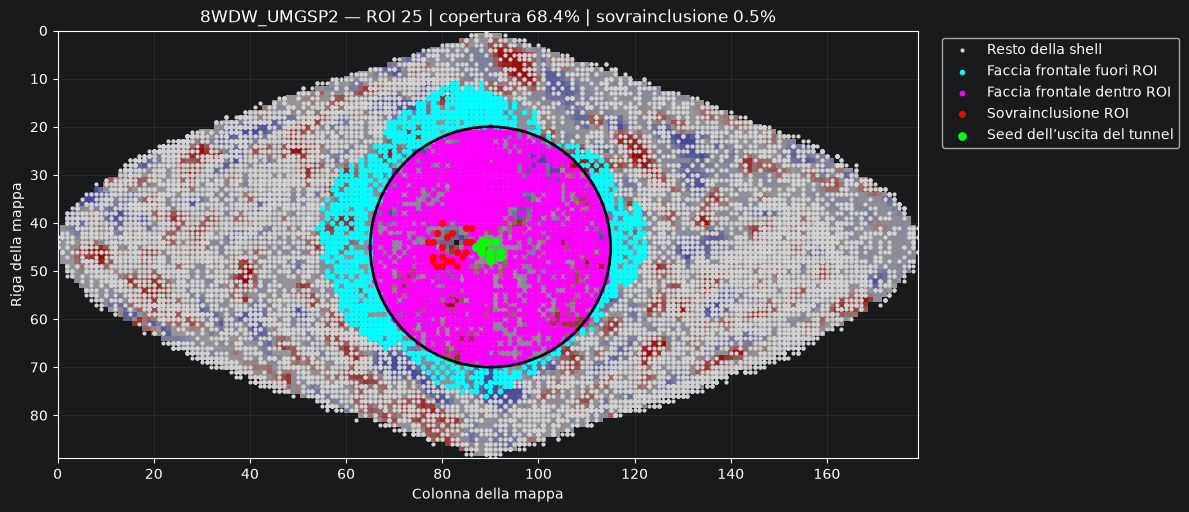

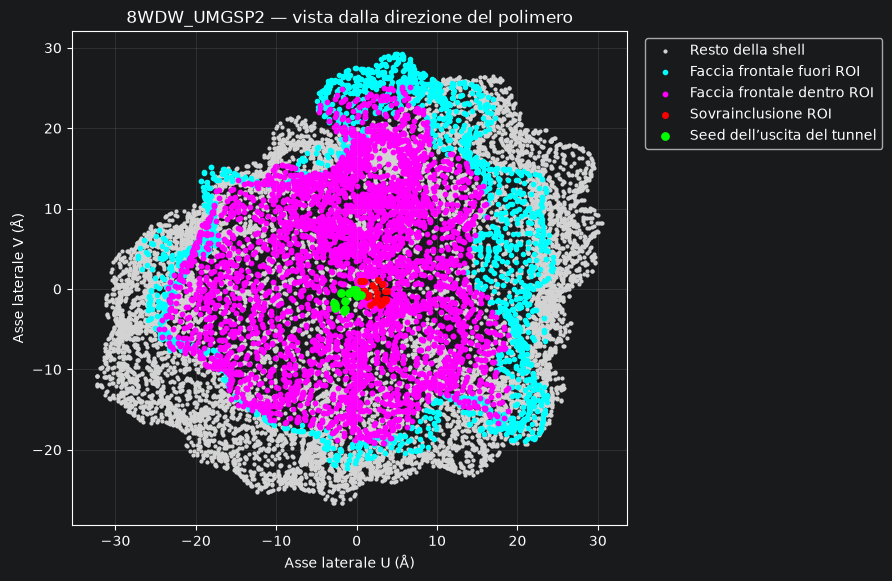

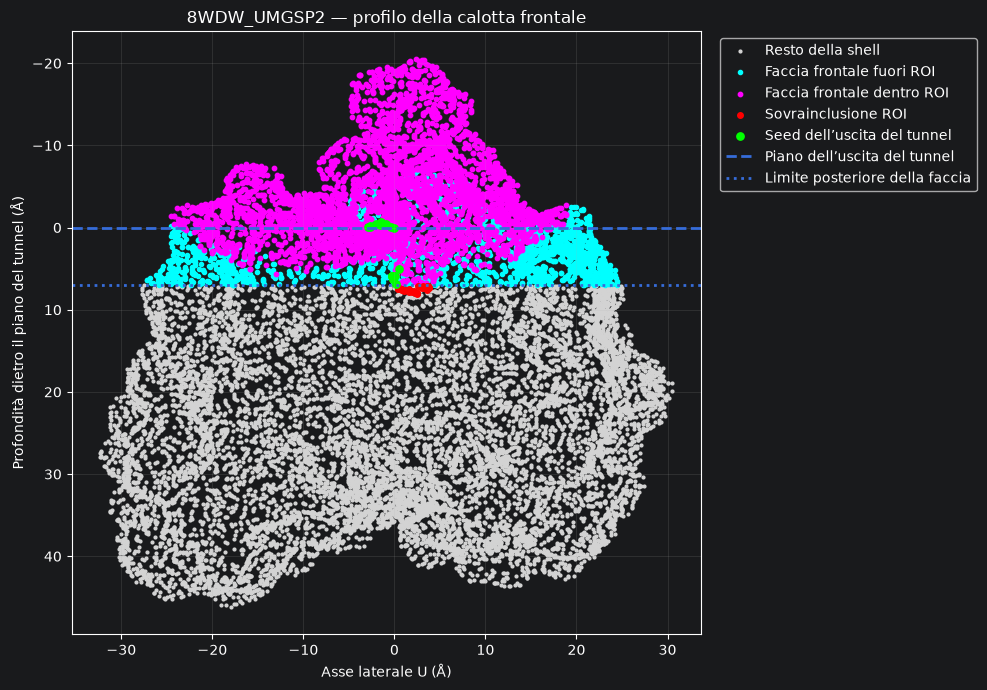

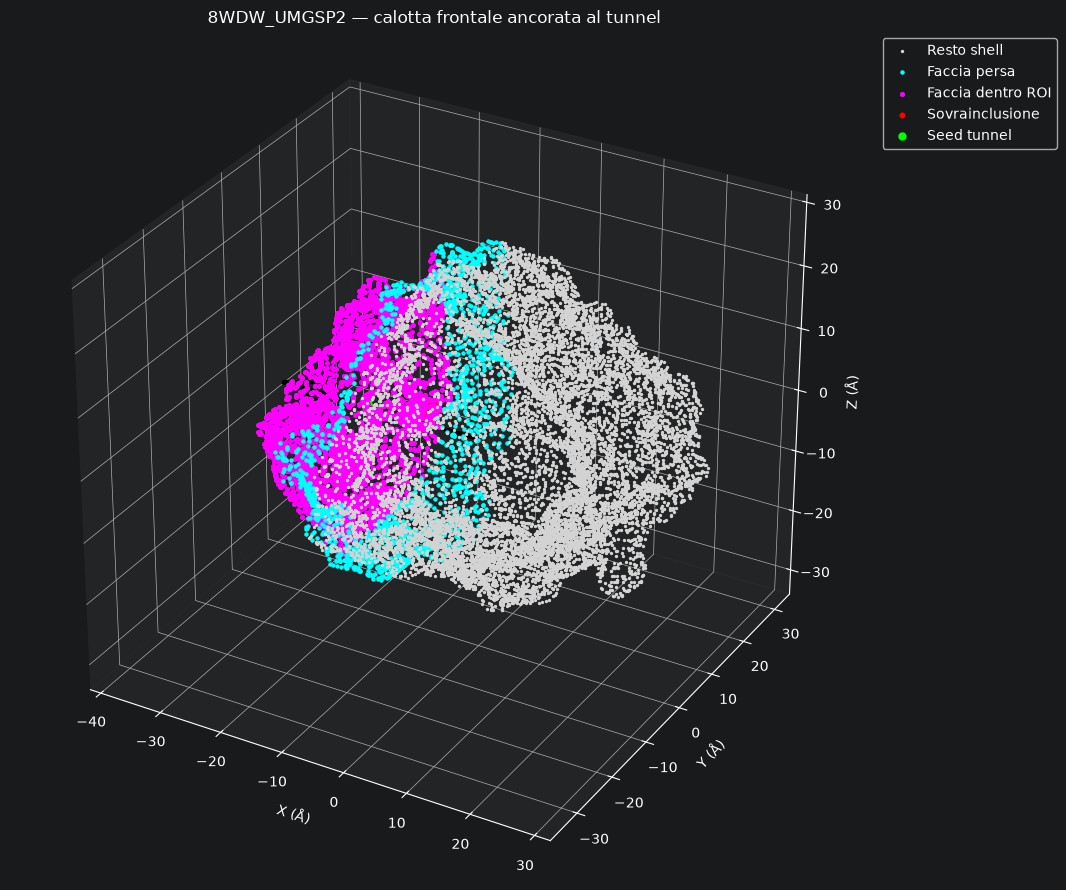

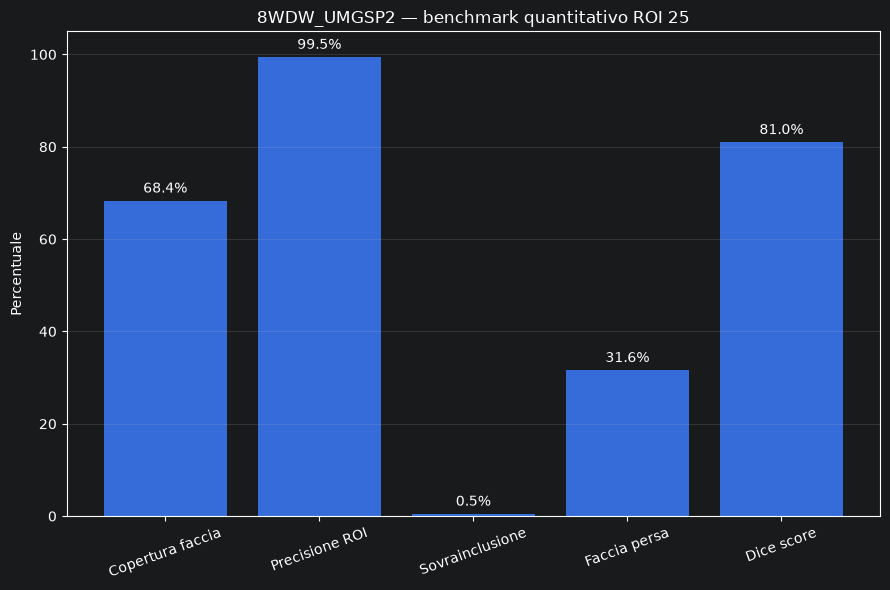

In [67]:
map_background = None

if SMOOTHED_MATRIX_FILE is not None:
    smooth_data = pd.read_csv(
        SMOOTHED_MATRIX_FILE,
        sep="\t",
    )

    if {
        "absc",
        "ord",
        "svalue",
    }.issubset(
        smooth_data.columns
    ):
        smooth_data[
            "svalue"
        ] = pd.to_numeric(
            smooth_data[
                "svalue"
            ],
            errors="coerce",
        )

        matrix_table = (
            smooth_data
            .pivot(
                index="ord",
                columns="absc",
                values="svalue",
            )
            .sort_index(
                axis=0
            )
            .sort_index(
                axis=1
            )
        )

        map_background = matrix_table.to_numpy(
            dtype=float,
            copy=True,
        )

        map_background[
            ~np.isfinite(
                map_background
            )
        ] = np.nan


plot_categories = [
    (
        "other_shell",
        "lightgray",
        4,
        "Resto della shell",
    ),
    (
        "missed_front_face",
        "cyan",
        9,
        "Faccia frontale fuori ROI",
    ),
    (
        "correct_roi",
        "magenta",
        10,
        "Faccia frontale dentro ROI",
    ),
    (
        "overincluded_roi",
        "red",
        16,
        "Sovrainclusione ROI",
    ),
    (
        "tunnel_seed",
        "lime",
        28,
        "Seed dell’uscita del tunnel",
    ),
]


# -------------------------------------------------------------------------
# Mappa Surfmap
# -------------------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(
        12,
        6,
    )
)

if map_background is not None:
    vmax = float(
        np.nanmax(
            np.abs(
                map_background
            )
        )
    )

    if (
        not np.isfinite(
            vmax
        )
        or vmax == 0
    ):
        vmax = 1.0

    axis.imshow(
        map_background,
        cmap="bwr_r",
        vmin=-vmax,
        vmax=vmax,
        interpolation="nearest",
        alpha=0.55,
    )


for column, color, size, label in plot_categories:
    mask = mapped_points[
        column
    ].to_numpy()

    axis.scatter(
        mapped_points.loc[
            mask,
            "map_col",
        ],
        mapped_points.loc[
            mask,
            "map_row",
        ],
        s=size,
        c=color,
        label=label,
    )


axis.add_patch(
    plt.Circle(
        (
            center_x,
            center_y,
        ),
        ROI_RADIUS,
        fill=False,
        color="black",
        linewidth=2,
    )
)

axis.set_xlim(
    0,
    MAP_WIDTH - 1,
)

axis.set_ylim(
    MAP_HEIGHT - 1,
    0,
)

axis.set_aspect(
    "equal"
)

axis.set_xlabel(
    "Colonna della mappa"
)

axis.set_ylabel(
    "Riga della mappa"
)

axis.set_title(
    f"{PROTEIN_NAME} — ROI 25 | "
    f"copertura {front_face_coverage_pct:.1f}% | "
    f"sovrainclusione {roi_overinclusion_pct:.1f}%"
)

axis.legend(
    loc="upper left",
    bbox_to_anchor=(
        1.02,
        1.0,
    ),
)

axis.grid(
    alpha=0.15
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Base ortonormale sul piano perpendicolare al tunnel
# -------------------------------------------------------------------------

reference_vector = np.array(
    [
        0.0,
        0.0,
        1.0,
    ]
)

if abs(
    np.dot(
        reference_vector,
        AXIS_UNIT,
    )
) > 0.95:
    reference_vector = np.array(
        [
            0.0,
            1.0,
            0.0,
        ]
    )


PLANE_U = np.cross(
    AXIS_UNIT,
    reference_vector,
)

PLANE_U = (
    PLANE_U
    / np.linalg.norm(
        PLANE_U
    )
)

PLANE_V = np.cross(
    AXIS_UNIT,
    PLANE_U,
)

PLANE_V = (
    PLANE_V
    / np.linalg.norm(
        PLANE_V
    )
)


mapped_points[
    "plane_u_A"
] = (
    shell_xyz
    @ PLANE_U
)

mapped_points[
    "plane_v_A"
] = (
    shell_xyz
    @ PLANE_V
)


# -------------------------------------------------------------------------
# Vista frontale fisica
# -------------------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(
        9,
        8,
    )
)

for column, color, size, label in plot_categories:
    mask = mapped_points[
        column
    ].to_numpy()

    axis.scatter(
        mapped_points.loc[
            mask,
            "plane_u_A",
        ],
        mapped_points.loc[
            mask,
            "plane_v_A",
        ],
        s=size,
        c=color,
        label=label,
    )


axis.set_aspect(
    "equal"
)

axis.set_xlabel(
    "Asse laterale U (Å)"
)

axis.set_ylabel(
    "Asse laterale V (Å)"
)

axis.set_title(
    f"{PROTEIN_NAME} — vista dalla direzione del polimero"
)

axis.grid(
    alpha=0.2
)

axis.legend(
    loc="upper left",
    bbox_to_anchor=(
        1.02,
        1.0,
    ),
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Profilo laterale: profondità dal piano del tunnel
# -------------------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(
        10,
        7,
    )
)

for column, color, size, label in plot_categories:
    mask = mapped_points[
        column
    ].to_numpy()

    axis.scatter(
        mapped_points.loc[
            mask,
            "plane_u_A",
        ],
        mapped_points.loc[
            mask,
            "front_depth_from_tunnel_A",
        ],
        s=size,
        c=color,
        label=label,
    )


axis.axhline(
    0.0,
    linestyle="--",
    linewidth=2,
    label="Piano dell’uscita del tunnel",
)

axis.axhline(
    FRONT_DEPTH_A,
    linestyle=":",
    linewidth=2,
    label="Limite posteriore della faccia",
)

axis.invert_yaxis()

axis.set_xlabel(
    "Asse laterale U (Å)"
)

axis.set_ylabel(
    "Profondità dietro il piano del tunnel (Å)"
)

axis.set_title(
    f"{PROTEIN_NAME} — profilo della calotta frontale"
)

axis.grid(
    alpha=0.2
)

axis.legend(
    loc="upper left",
    bbox_to_anchor=(
        1.02,
        1.0,
    ),
)

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Vista 3D
# -------------------------------------------------------------------------

figure = plt.figure(
    figsize=(
        11,
        9,
    )
)

axis3d = figure.add_subplot(
    111,
    projection="3d",
)


for column, color, size, label in [
    (
        "other_shell",
        "lightgray",
        2,
        "Resto shell",
    ),
    (
        "missed_front_face",
        "cyan",
        5,
        "Faccia persa",
    ),
    (
        "correct_roi",
        "magenta",
        7,
        "Faccia dentro ROI",
    ),
    (
        "overincluded_roi",
        "red",
        11,
        "Sovrainclusione",
    ),
    (
        "tunnel_seed",
        "lime",
        25,
        "Seed tunnel",
    ),
]:
    mask = mapped_points[
        column
    ].to_numpy()

    axis3d.scatter(
        mapped_points.loc[
            mask,
            "x",
        ],
        mapped_points.loc[
            mask,
            "y",
        ],
        mapped_points.loc[
            mask,
            "z",
        ],
        s=size,
        c=color,
        label=label,
        depthshade=False,
    )


axis_length = float(
    np.nanpercentile(
        np.linalg.norm(
            shell_xyz,
            axis=1,
        ),
        95,
    )
)

axis3d.quiver(
    0,
    0,
    0,
    AXIS_UNIT[0],
    AXIS_UNIT[1],
    AXIS_UNIT[2],
    length=axis_length,
    normalize=True,
    linewidth=3,
    color="black",
)

axis3d.set_xlabel(
    "X (Å)"
)

axis3d.set_ylabel(
    "Y (Å)"
)

axis3d.set_zlabel(
    "Z (Å)"
)

axis3d.set_title(
    f"{PROTEIN_NAME} — calotta frontale ancorata al tunnel"
)

axis3d.legend(
    loc="upper left",
    bbox_to_anchor=(
        1.02,
        1.0,
    ),
)

try:
    axis3d.set_box_aspect(
        np.ptp(
            shell_xyz,
            axis=0,
        )
    )
except Exception:
    pass

plt.tight_layout()
plt.show()


# -------------------------------------------------------------------------
# Benchmark sintetico
# -------------------------------------------------------------------------

metric_names = [
    "Copertura faccia",
    "Precisione ROI",
    "Sovrainclusione",
    "Faccia persa",
    "Dice score",
]

metric_values = [
    front_face_coverage_pct,
    roi_precision_pct,
    roi_overinclusion_pct,
    missed_front_face_pct,
    dice_score_pct,
]


figure, axis = plt.subplots(
    figsize=(
        9,
        6,
    )
)

bars = axis.bar(
    metric_names,
    metric_values,
)

for bar, value in zip(
    bars,
    metric_values,
):
    axis.text(
        bar.get_x()
        + bar.get_width()
        / 2.0,
        bar.get_height()
        + 1.0,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
    )

axis.set_ylim(
    0,
    105,
)

axis.set_ylabel(
    "Percentuale"
)

axis.set_title(
    f"{PROTEIN_NAME} — benchmark quantitativo ROI 25"
)

axis.tick_params(
    axis="x",
    rotation=20,
)

axis.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()
plt.show()


## Cella 8 — Sensibilità alla profondità della faccia

Il parametro che separa faccia e regioni laterali/posteriori è ora la
profondità rispetto al piano del tunnel.

La cella ricalcola la classificazione per più profondità, mantenendo invariati
centro, raggio della ROI e continuità tridimensionale.


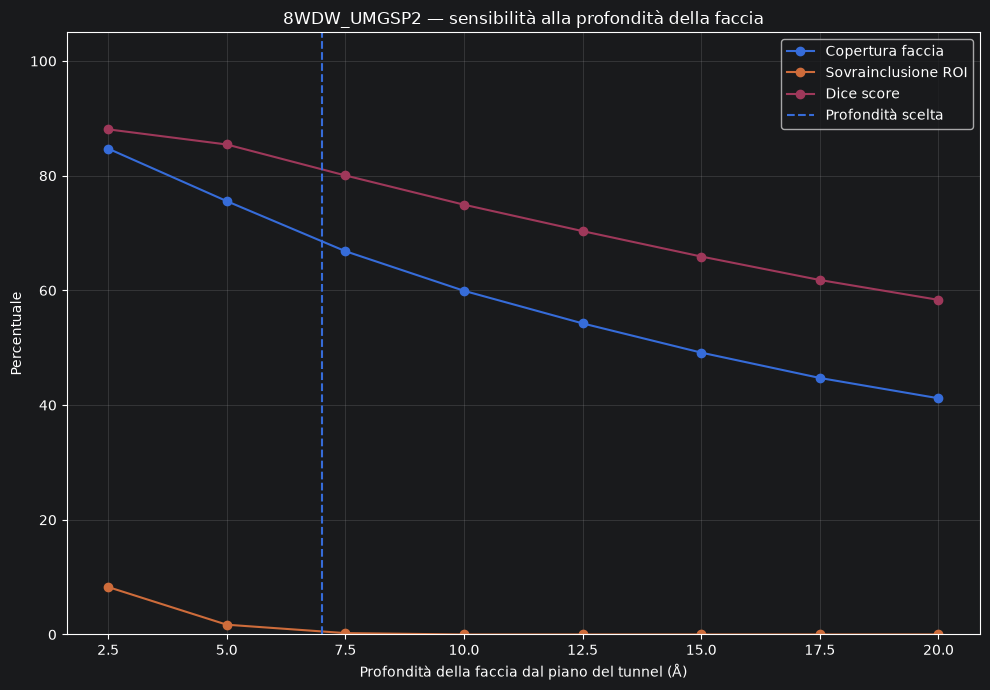

,front_depth_A,candidate_points,front_face_points,front_face_coverage_pct,roi_overinclusion_pct,dice_score_pct
0,2.5,4815,4815,84.724429,8.278093,88.084415
1,5.0,5800,5800,75.565936,1.708669,85.443382
2,7.5,6635,6635,66.836784,0.243680,80.044029
3,10.0,7433,7433,59.930139,0.000000,74.945398
4,12.5,8226,8226,54.247048,0.000000,70.337875
5,15.0,9020,9020,49.151149,0.000000,65.907838
6,17.5,9898,9898,44.731391,0.000000,61.812978
7,20.0,10797,10797,41.192005,0.000000,58.348920


In [68]:
sensitivity_rows = []


for tested_depth in FRONT_DEPTH_VALUES_TO_TEST:
    tested_face, tested_candidates = build_tunnel_depth_face(
        float(
            tested_depth
        )
    )

    tested_correct = (
        roi_mask
        & tested_face
    )

    tested_over = (
        roi_mask
        & ~tested_face
    )

    tested_missed = (
        ~roi_mask
        & tested_face
    )


    tested_correct_weight = weighted_sum(
        tested_correct
    )

    tested_over_weight = weighted_sum(
        tested_over
    )

    tested_missed_weight = weighted_sum(
        tested_missed
    )

    tested_roi_weight = (
        tested_correct_weight
        + tested_over_weight
    )

    tested_face_weight = (
        tested_correct_weight
        + tested_missed_weight
    )


    tested_over_pct = (
        100.0
        * tested_over_weight
        / tested_roi_weight
        if tested_roi_weight
        else np.nan
    )

    tested_coverage_pct = (
        100.0
        * tested_correct_weight
        / tested_face_weight
        if tested_face_weight
        else np.nan
    )


    tested_denominator = (
        2.0
        * tested_correct_weight
        + tested_over_weight
        + tested_missed_weight
    )

    tested_dice_pct = (
        100.0
        * 2.0
        * tested_correct_weight
        / tested_denominator
        if tested_denominator
        else np.nan
    )


    sensitivity_rows.append({
        "front_depth_A": float(
            tested_depth
        ),
        "candidate_points": int(
            tested_candidates.sum()
        ),
        "front_face_points": int(
            tested_face.sum()
        ),
        "front_face_coverage_pct": tested_coverage_pct,
        "roi_overinclusion_pct": tested_over_pct,
        "dice_score_pct": tested_dice_pct,
    })


sensitivity_table = pd.DataFrame(
    sensitivity_rows
)


figure, axis = plt.subplots(
    figsize=(
        10,
        7,
    )
)

axis.plot(
    sensitivity_table[
        "front_depth_A"
    ],
    sensitivity_table[
        "front_face_coverage_pct"
    ],
    marker="o",
    label="Copertura faccia",
)

axis.plot(
    sensitivity_table[
        "front_depth_A"
    ],
    sensitivity_table[
        "roi_overinclusion_pct"
    ],
    marker="o",
    label="Sovrainclusione ROI",
)

axis.plot(
    sensitivity_table[
        "front_depth_A"
    ],
    sensitivity_table[
        "dice_score_pct"
    ],
    marker="o",
    label="Dice score",
)

axis.axvline(
    FRONT_DEPTH_A,
    linestyle="--",
    label="Profondità scelta",
)

axis.set_xlabel(
    "Profondità della faccia dal piano del tunnel (Å)"
)

axis.set_ylabel(
    "Percentuale"
)

axis.set_ylim(
    0,
    105,
)

axis.set_title(
    f"{PROTEIN_NAME} — sensibilità alla profondità della faccia"
)

axis.grid(
    alpha=0.25
)

axis.legend()

plt.tight_layout()
plt.show()


display(
    sensitivity_table
)


## Cella 9 — Export CSV, PDB and script PyMOL


In [69]:
correct_points_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_correct_front_points_7.pdb"
overincluded_points_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_overincluded_points_7.pdb"
missed_points_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_missed_front_points_7.pdb"
seed_points_path = OUTPUT_DIR / f"{PROTEIN_NAME}_tunnel_seed_points_7.pdb"
point_csv_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_point_classification_7.csv"
residue_csv_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_residue_classification_7.csv"
summary_csv_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_quantitative_summary_7.csv"
sensitivity_csv_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_front_depth_sensitivity_7.csv"
pymol_script_path = OUTPUT_DIR / f"{PROTEIN_NAME}_ROI25_tunnel_plane_front_face_visualize_7.pml"

write_pseudoatom_pdb(
    correct_points_path,
    mapped_points[mapped_points["correct_roi"]],
    "COR",
)
write_pseudoatom_pdb(
    overincluded_points_path,
    mapped_points[mapped_points["overincluded_roi"]],
    "OVR",
)
write_pseudoatom_pdb(
    missed_points_path,
    mapped_points[mapped_points["missed_front_face"]],
    "MIS",
)
write_pseudoatom_pdb(
    seed_points_path,
    mapped_points[mapped_points["tunnel_seed"]],
    "SED",
)

mapped_points.to_csv(point_csv_path, index=False)
residue_table.to_csv(residue_csv_path, index=False)
quantitative_summary.to_csv(summary_csv_path, index=False)
sensitivity_table.to_csv(sensitivity_csv_path, index=False)

predominantly_overincluded = residue_table[
    residue_table["predominantly_overincluded"]
]
predominantly_missed = residue_table[
    residue_table["predominantly_missed"]
]
correct_residues = residue_table[
    (residue_table["correct_surface_proxy"] > 0)
    & ~residue_table["predominantly_overincluded"]
    & ~residue_table["predominantly_missed"]
]

over_selection = pymol_residue_selection(predominantly_overincluded)
missed_selection = pymol_residue_selection(predominantly_missed)
correct_selection = pymol_residue_selection(correct_residues)

with pymol_script_path.open("w", encoding="utf-8") as handle:
    handle.write("reinitialize\n")
    handle.write(f'load "{ALIGNED_PROTEIN_PDB_FILE.as_posix()}", protein\n')
    handle.write("hide everything, protein\n")
    handle.write("show cartoon, protein\n")
    handle.write("show surface, protein\n")
    handle.write("color gray80, protein\n")
    handle.write("set transparency, 0.55, protein\n")

    handle.write(
        f"select roi25_correct_residues, protein and ({correct_selection})\n"
    )
    handle.write(
        f"select roi25_overincluded_residues, protein and ({over_selection})\n"
    )
    handle.write(
        f"select roi25_missed_front_residues, protein and ({missed_selection})\n"
    )
    handle.write("color magenta, roi25_correct_residues\n")
    handle.write("color red, roi25_overincluded_residues\n")
    handle.write("color cyan, roi25_missed_front_residues\n")
    handle.write("show sticks, roi25_overincluded_residues\n")
    handle.write("show sticks, roi25_missed_front_residues\n")

    handle.write(f'load "{correct_points_path.as_posix()}", roi25_correct_front_points\n')
    handle.write(f'load "{overincluded_points_path.as_posix()}", roi25_overincluded_points\n')
    handle.write(f'load "{missed_points_path.as_posix()}", roi25_missed_front_points\n')
    handle.write(f'load "{seed_points_path.as_posix()}", tunnel_seed_points\n')

    handle.write(
        "hide everything, roi25_correct_front_points or "
        "roi25_overincluded_points or roi25_missed_front_points or "
        "tunnel_seed_points\n"
    )
    handle.write(
        "show spheres, roi25_correct_front_points or "
        "roi25_overincluded_points or roi25_missed_front_points or "
        "tunnel_seed_points\n"
    )
    handle.write(
        f"set sphere_scale, {PYMOL_SPHERE_SCALE}, "
        "roi25_correct_front_points or roi25_overincluded_points or "
        "roi25_missed_front_points\n"
    )
    handle.write(
        f"set sphere_scale, {PYMOL_SPHERE_SCALE * 1.8}, tunnel_seed_points\n"
    )
    handle.write("color magenta, roi25_correct_front_points\n")
    handle.write("color red, roi25_overincluded_points\n")
    handle.write("color cyan, roi25_missed_front_points\n")
    handle.write("color green, tunnel_seed_points\n")
    handle.write("bg_color white\n")
    handle.write(
        "zoom roi25_correct_front_points or roi25_overincluded_points or "
        "roi25_missed_front_points, 5\n"
    )

print("Creato:", correct_points_path)
print("Creato:", overincluded_points_path)
print("Creato:", missed_points_path)
print("Creato:", seed_points_path)
print("Creato:", point_csv_path)
print("Creato:", residue_csv_path)
print("Creato:", summary_csv_path)
print("Creato:", sensitivity_csv_path)
print("Creato:", pymol_script_path)


Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_ROI25_correct_front_points_7.pdb
Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_ROI25_overincluded_points_7.pdb
Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_ROI25_missed_front_points_7.pdb
Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_tunnel_seed_points_7.pdb
Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_ROI25_point_classification_7.csv
Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_ROI25_residue_classification_7.csv
Creato: /home/chiara/Desktop/COMENZE/Comenze_pipeline/Surface_analysis/SURFMAP_VALIDATION/SURFMAP_ROI/8WDW_UMGSP2_ROI25_quanti

# Lettura del risultato

## Proteina più grande

Usa soprattutto:

- `front_face_coverage_pct`;
- percentuale e residui ciano;
- stabilità della copertura al variare di `FRONT_DEPTH_A`.

## Proteina più piccola

Usa soprattutto:

- `roi_overinclusion_pct`;
- numero dei residui prevalentemente sovrainclusi;
- posizione dei punti e residui rossi;
- profilo laterale rispetto al piano del tunnel.

## Perché questa versione corregge il problema precedente

La vecchia classificazione usava l’orientamento delle normali locali. Con una
soglia vicina a 90° poteva estendersi sulle superfici laterali, mentre normali
rumorose o pareti curve vicino al tunnel potevano essere escluse.

Questa versione usa invece:

- un piano ancorato all’uscita del tunnel;
- una profondità assiale esplicita;
- nessun limite di larghezza o altezza;
- la componente tridimensionale connessa ai seed centrali.

## PyMOL

```text
@C:/percorso/NOME_PROTEINA_ROI25_tunnel_plane_front_face_visualize.pml
```

- magenta: faccia inclusa;
- rosso: sovrainclusione;
- ciano: faccia persa;
- verde: seed del tunnel.
